# LASV survivor durability analysis: time since discharge, age, and sex

Within confirmed Lassa fever survivors with a known date of discharge (DoDis), this notebook tests whether antibody phenotypes vary with **years since discharge**, **age**, and **sex**.

Primary analyses:
1. Cohort QC and confounding checks.
2. NP ELISA, GP ELISA, neutralization, and high-specificity LASV PhIP-Seq breadth vs years since discharge.
3. Multivariable models adjusted for age and sex.
4. Peptide-level logistic regression: `reactive ~ years_since_discharge + age_years + sex`.
5. BH-FDR correction separately for time, age, and sex effects.

The default analysis uses one baseline/first sample per survivor to preserve independence.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning

META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
PEP_META_FILE = Path('./metadata_files/lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')
OUTDIR = Path('./output_figures/DoDis_analysis')
OUTDIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 11,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'svg.fonttype': 'none', 'pdf.fonttype': 42,
})

SURVIVOR_COLOR = '#D55E00'  # Okabe-Ito vermillion


In [2]:
# Load data
sample_meta = pd.read_csv(META_FILE)
df = pd.read_csv(LONG_FILE)
peps_meta = pd.read_csv(PEP_META_FILE)
peps_metadata = peps_meta.set_index('seq_id')

for c in ['collection_date', 'discharge_date']:
    sample_meta[c] = pd.to_datetime(sample_meta[c], errors='coerce')
for c in ['years_since_discharge','age_years','NP_Calc_Conc','GP_Calc_Conc','Neut_Percent']:
    if c in sample_meta.columns:
        sample_meta[c] = pd.to_numeric(sample_meta[c], errors='coerce')

print('metadata:', sample_meta.shape)
print('long PhIP:', df.shape)


metadata: (884, 49)
long PhIP: (2266572, 13)


/tmp/ipykernel_3260321/1934561372.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_meta[c] = pd.to_datetime(sample_meta[c], errors='coerce')
/tmp/ipykernel_3260321/1934561372.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_meta[c] = pd.to_datetime(sample_meta[c], errors='coerce')


In [3]:
# One baseline/first sample per participant
sample_meta_baseline = (
    sample_meta.sort_values(['participant_id','collection_date'])
    .drop_duplicates('participant_id', keep='first')
    .copy()
)

# Confirmed survivors with known DoDis and required demographic covariates
survivors = sample_meta_baseline.loc[
    (sample_meta_baseline['Category'] == 'S') &
    sample_meta_baseline['years_since_discharge'].notna()
].copy()

print('Baseline survivors:', (sample_meta_baseline['Category']=='S').sum())
print('Survivors with DoDis:', len(survivors))
print('Missing age:', survivors['age_years'].isna().sum())
print('Missing sex:', survivors['sex'].isna().sum())
display(survivors[['participant_id','sample_id','years_since_discharge','age_years','sex']].head())


Baseline survivors: 125
Survivors with DoDis: 88
Missing age: 1
Missing sex: 0


,participant_id,sample_id,years_since_discharge,age_years,sex
552,S-104,S-104_SA1_A3,8.52,43.0,Female
554,S-105,S-105_SA1_A4,2.69,10.0,Male
556,S-106,S-106_SA1_A8,2.65,7.0,Male
557,S-107,S-107_SA1_A9,4.89,12.0,Female
561,S-109,S-109_SA1_B1,0.08,15.0,Female


In [20]:
survivors.columns

Index(['sample_id', 'participant_id', 'lassa_ID', 'lassa_Enrolled_Type',
       'Category', 'collection_date', 'collection_year', 'collection_month',
       'collection_year_month', 'baseline_date', 'visit_number',
       'days_since_baseline', 'years_since_baseline',
       'days_since_previous_visit', 'discharge_date', 'years_since_discharge',
       'days_since_discharge', 'NP_Calc_Conc', 'NP_FINAL_RESULT',
       'GP_Calc_Conc', 'GP_FINAL_RESULT', 'Serology_Result_Corrected',
       'Serology_Positive', 'ELISA_complete', 'Neut_Percent', 'Neut_Result',
       'sex', 'age_years', 'district', 'chiefdom', 'village',
       'demo_occupation', 'demo_marital_status', 'inventory_location',
       'inventory_box_aliquot', 'inventory_name', 'HL.L.SEV', 'HL.R.SEV',
       'type', 'DIFF.STATUS', 'hearing_present', 'lassa_District',
       'lassa_Chiefdom', 'lassa_VillageTown', 'missing_sex',
       'missing_age_years', 'missing_district', 'missing_chiefdom',
       'missing_village'],
      dt

In [22]:
survivors.sort_values(by='years_since_discharge')[['years_since_discharge', 'discharge_date', 'baseline_date', 'sample_id']]

,years_since_discharge,discharge_date,baseline_date,sample_id
762,0.05,2016-09-15,10/2/16,S-192_SA1_F4
875,0.06,2020-11-09,12/2/20,S-510_SA3_D5
561,0.08,2016-03-02,4/1/16,S-109_SA1_B1
592,0.15,2016-02-06,4/1/16,S-115_SA1_A5
565,0.42,2015-10-31,4/1/16,S-110_SA1_B2
...,...,...,...,...
650,25.79,1990-06-20,4/5/16,S-132_SA1_C9
666,26.12,1990-02-20,4/5/16,S-137_SA1_D4
801,28.94,1990-10-15,9/24/19,S-450_SA4_B3
865,29.26,1991-08-28,12/2/20,S-504_SA3_D8


,count,mean,std,min,25%,50%,75%,max
years_since_discharge,88.0,10.341250,7.803963,0.050000,3.715000,9.090000,15.455000,29.480000
age_years,87.0,31.367816,13.985137,7.000000,20.000000,30.000000,40.500000,75.000000
NP_Calc_Conc,88.0,37.627554,55.811366,0.637119,6.892735,16.268877,42.387903,310.652203
GP_Calc_Conc,88.0,11.314507,20.065277,0.544463,1.483838,4.091511,12.586968,133.726960
Neut_Percent,88.0,69.548450,24.105378,0.000000,58.159759,76.747292,86.914786,95.695282



Sex:
sex
Female    57
Male      31
Name: count, dtype: int64
Age vs years since discharge: Spearman rho=0.287, P=7.043e-03, n=87


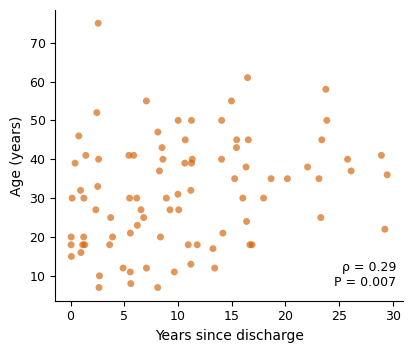

In [4]:
# Cohort summary / QC
display(survivors[['years_since_discharge','age_years','NP_Calc_Conc','GP_Calc_Conc','Neut_Percent']].describe().T)
print()
print('Sex:')
print(survivors['sex'].value_counts(dropna=False))

qc = survivors[['years_since_discharge','age_years']].dropna()
rho_age_time, p_age_time = spearmanr(qc['years_since_discharge'], qc['age_years'])
print(f'Age vs years since discharge: Spearman rho={rho_age_time:.3f}, P={p_age_time:.3e}, n={len(qc)}')

fig, ax = plt.subplots(figsize=(4.2,3.6))
ax.scatter(qc['years_since_discharge'], qc['age_years'], s=25, alpha=.65, color=SURVIVOR_COLOR, edgecolor='none')
ax.set_xlabel('Years since discharge')
ax.set_ylabel('Age (years)')
ax.text(.98,.04,f'ρ = {rho_age_time:.2f}\nP = {p_age_time:.2g}',transform=ax.transAxes,ha='right',va='bottom')
fig.tight_layout()
plt.show()


In [5]:
# Restrict PhIP data to these survivor baseline samples and LASV peptides
survivor_ids = set(survivors['sample_id'])
lasv_surv = df.loc[
    df['individual'].isin(survivor_ids) &
    df['species'].eq('Mammarenavirus lassaense')
].copy()

print('Survivor PhIP samples:', lasv_surv['individual'].nunique())
print('LASV peptides:', lasv_surv['peptide'].nunique())
print(lasv_surv['protein_std'].value_counts())


Survivor PhIP samples: 84
LASV peptides: 246
protein_std
polymerase       16212
nucleoprotein     2436
glycoprotein      1344
z protein          672
Name: count, dtype: int64


In [6]:
# High-specificity LASV peptide breadth by protein
breadth = (
    lasv_surv.groupby(['individual','protein_std'])['reactive']
    .sum().unstack(fill_value=0).reset_index()
    .rename(columns={
        'nucleoprotein':'NP_breadth', 'glycoprotein':'GPC_breadth',
        'polymerase':'L_breadth', 'z protein':'Z_breadth'
    })
)
protein_breadth_cols = [c for c in ['NP_breadth','GPC_breadth','L_breadth','Z_breadth'] if c in breadth.columns]
breadth['LASV_breadth'] = breadth[protein_breadth_cols].sum(axis=1)

analysis = survivors.merge(breadth, left_on='sample_id', right_on='individual', how='left', validate='one_to_one')
for c in protein_breadth_cols + ['LASV_breadth']:
    analysis[c] = analysis[c].fillna(0)

print('Analysis survivors:', len(analysis))
display(analysis[['participant_id','years_since_discharge','age_years','sex','LASV_breadth'] + protein_breadth_cols].head())


Analysis survivors: 88


,participant_id,years_since_discharge,age_years,sex,LASV_breadth,NP_breadth,GPC_breadth,L_breadth,Z_breadth
0,S-104,8.52,43.0,Female,14.0,5.0,3.0,6.0,0.0
1,S-105,2.69,10.0,Male,37.0,9.0,12.0,15.0,1.0
2,S-106,2.65,7.0,Male,37.0,17.0,8.0,12.0,0.0
3,S-107,4.89,12.0,Female,38.0,15.0,10.0,13.0,0.0
4,S-109,0.08,15.0,Female,34.0,18.0,4.0,11.0,1.0


## Whole-assay durability

First visualize unadjusted relationships. The regression table below then adjusts for age and sex. ELISA concentrations are analyzed after `log1p` transformation. Neutralization is analyzed as `Neut_Percent` as currently encoded in the metadata; if you later substitute a true neutralization titer, use log-transformed titer instead.


In [7]:
# Unadjusted Spearman correlations with years since discharge
outcomes = [c for c in ['NP_Calc_Conc','GP_Calc_Conc','Neut_Percent','LASV_breadth','NP_breadth','GPC_breadth'] if c in analysis.columns]
corr_rows=[]
for outcome in outcomes:
    tmp=analysis[['years_since_discharge',outcome]].dropna()
    if len(tmp) >= 5 and tmp[outcome].nunique() > 1:
        rho,p=spearmanr(tmp['years_since_discharge'],tmp[outcome])
        corr_rows.append({'outcome':outcome,'n':len(tmp),'rho':rho,'p_value':p})
corr=pd.DataFrame(corr_rows)
if len(corr):
    corr['FDR']=multipletests(corr['p_value'],method='fdr_bh')[1]
display(corr)


,outcome,n,rho,p_value,FDR
0,NP_Calc_Conc,88,-0.332359,0.001558,0.009057
1,GP_Calc_Conc,88,-0.278697,0.008555,0.017110
2,Neut_Percent,88,-0.256317,0.015931,0.020220
3,LASV_breadth,88,-0.250525,0.018562,0.020220
4,NP_breadth,88,-0.312659,0.003019,0.009057
5,GPC_breadth,88,-0.247230,0.020220,0.020220


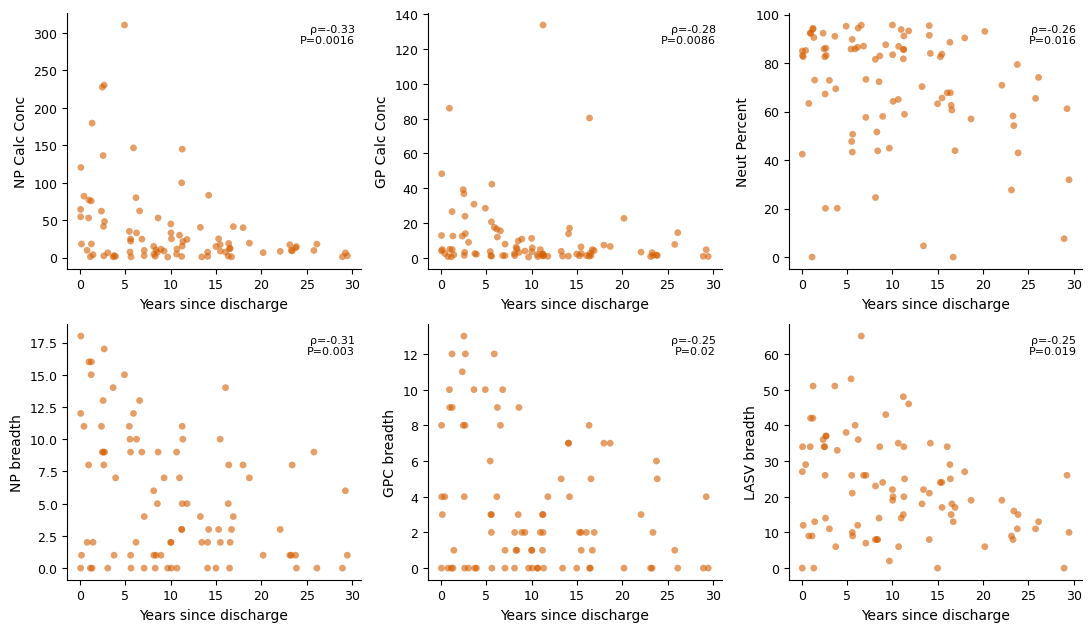

In [8]:
# Publication-style scatter panels
plot_outcomes = [c for c in ['NP_Calc_Conc','GP_Calc_Conc','Neut_Percent','NP_breadth','GPC_breadth','LASV_breadth'] if c in analysis.columns]
fig, axes = plt.subplots(2, 3, figsize=(11,6.4))
axes=axes.flat
for ax,outcome in zip(axes,plot_outcomes):
    tmp=analysis[['years_since_discharge',outcome]].dropna()
    ax.scatter(tmp['years_since_discharge'],tmp[outcome],s=24,alpha=.6,color=SURVIVOR_COLOR,edgecolor='none')
    if len(tmp)>=5 and tmp[outcome].nunique()>1:
        rho,p=spearmanr(tmp['years_since_discharge'],tmp[outcome])
        ax.text(.98,.96,f'ρ={rho:.2f}\nP={p:.2g}',transform=ax.transAxes,ha='right',va='top',fontsize=8)
    ax.set_xlabel('Years since discharge')
    ax.set_ylabel(outcome.replace('_',' '))
for ax in list(axes)[len(plot_outcomes):]: ax.axis('off')
fig.tight_layout()
fig.savefig(OUTDIR/'DoDis_whole_assay_scatter.svg',bbox_inches='tight')
fig.savefig(OUTDIR/'DoDis_whole_assay_scatter.pdf',bbox_inches='tight')
plt.show()


In [9]:
# Multivariable whole-assay models adjusted for age + sex
# Continuous breadth is modeled with negative-binomial GLM; ELISA/neut with OLS after log1p where appropriate.
whole_rows=[]

def fit_continuous(outcome, log1p=True):
    cols=[outcome,'years_since_discharge','age_years','sex']
    dat=analysis[cols].dropna().copy()
    if len(dat)<10 or dat[outcome].nunique()<2: return
    dat['y']=np.log1p(dat[outcome]) if log1p else dat[outcome]
    try:
        fit=smf.ols('y ~ years_since_discharge + age_years + C(sex)',data=dat).fit(cov_type='HC3')
        whole_rows.append({'outcome':outcome,'model':'OLS log1p' if log1p else 'OLS','n':len(dat),
                           'beta_time':fit.params.get('years_since_discharge',np.nan),
                           'p_time':fit.pvalues.get('years_since_discharge',np.nan),
                           'beta_age':fit.params.get('age_years',np.nan),
                           'p_age':fit.pvalues.get('age_years',np.nan)})
    except Exception as e: print('Failed',outcome,e)

def fit_count(outcome):
    dat=analysis[[outcome,'years_since_discharge','age_years','sex']].dropna().copy()
    if len(dat)<10 or dat[outcome].nunique()<2: return
    try:
        fit=smf.glm(f'{outcome} ~ years_since_discharge + age_years + C(sex)',data=dat,family=sm.families.NegativeBinomial()).fit()
        whole_rows.append({'outcome':outcome,'model':'Negative binomial','n':len(dat),
                           'beta_time':fit.params.get('years_since_discharge',np.nan),
                           'p_time':fit.pvalues.get('years_since_discharge',np.nan),
                           'beta_age':fit.params.get('age_years',np.nan),
                           'p_age':fit.pvalues.get('age_years',np.nan)})
    except Exception as e: print('Failed',outcome,e)

for o in [c for c in ['NP_Calc_Conc','GP_Calc_Conc'] if c in analysis.columns]: fit_continuous(o,True)
if 'Neut_Percent' in analysis.columns: fit_continuous('Neut_Percent',False)
for o in [c for c in ['LASV_breadth','NP_breadth','GPC_breadth'] if c in analysis.columns]: fit_count(o)
whole_models=pd.DataFrame(whole_rows)
if len(whole_models): whole_models['FDR_time']=multipletests(whole_models['p_time'].fillna(1),method='fdr_bh')[1]
display(whole_models)


/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "
/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "
/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/statsmodels/genmod/families/family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "


,outcome,model,n,beta_time,p_time,beta_age,p_age,FDR_time
0,NP_Calc_Conc,OLS log1p,87,-0.053783,0.001266,0.000714,0.948894,0.007594
1,GP_Calc_Conc,OLS log1p,87,-0.030278,0.031163,-0.014959,0.052580,0.037396
2,Neut_Percent,OLS,87,-0.861866,0.019237,0.127582,0.498810,0.028856
3,LASV_breadth,Negative binomial,87,-0.025043,0.092096,-0.005762,0.484630,0.092096
4,NP_breadth,Negative binomial,87,-0.042472,0.008925,-0.009055,0.304389,0.017850
5,GPC_breadth,Negative binomial,87,-0.045630,0.007756,0.002583,0.776915,0.017850


## Peptide-level multivariable logistic regression

For each LASV peptide, model `reactive ~ years_since_discharge + age_years + sex`. The primary effect is the odds ratio per additional year since discharge. Models with very sparse reactivity or numerical failure are retained as QC failures rather than silently interpreted.


In [10]:
# Build participant x peptide Boolean matrix
pep_wide = lasv_surv.pivot(index='individual',columns='peptide',values='reactive')
pep_wide = pep_wide.fillna(False).astype(bool)
model_meta = analysis.set_index('sample_id')[['years_since_discharge','age_years','sex']]
pep_model = pep_wide.join(model_meta, how='inner')
pep_model = pep_model.dropna(subset=['years_since_discharge','age_years','sex']).copy()
print('Complete-case survivors for peptide models:',len(pep_model))
print('Peptides:',pep_wide.shape[1])


Complete-case survivors for peptide models: 83
Peptides: 246


In [11]:
def run_peptide_logistic_models(data, peptide_cols, min_positive=5, min_negative=5):
    rows=[]
    for peptide in peptide_cols:
        dat=data[[peptide,'years_since_discharge','age_years','sex']].copy()
        dat['reactive']=dat[peptide].astype(int)
        n_pos=int(dat['reactive'].sum()); n_neg=len(dat)-n_pos
        base={'peptide':peptide,'n':len(dat),'n_reactive':n_pos,'n_nonreactive':n_neg}
        if n_pos < min_positive or n_neg < min_negative:
            rows.append({**base,'status':'too_sparse'}); continue
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', PerfectSeparationWarning)
                fit=smf.logit('reactive ~ years_since_discharge + age_years + C(sex)',data=dat).fit(disp=False,maxiter=200)
            sex_terms=[x for x in fit.params.index if x.startswith('C(sex)')]
            sex_term=sex_terms[0] if len(sex_terms)==1 else None
            rows.append({**base,'status':'ok',
                'beta_time':fit.params.get('years_since_discharge',np.nan),'OR_time':np.exp(fit.params.get('years_since_discharge',np.nan)),'p_time':fit.pvalues.get('years_since_discharge',np.nan),
                'beta_age':fit.params.get('age_years',np.nan),'OR_age':np.exp(fit.params.get('age_years',np.nan)),'p_age':fit.pvalues.get('age_years',np.nan),
                'sex_term':sex_term,'beta_sex':fit.params.get(sex_term,np.nan) if sex_term else np.nan,'OR_sex':np.exp(fit.params.get(sex_term,np.nan)) if sex_term else np.nan,'p_sex':fit.pvalues.get(sex_term,np.nan) if sex_term else np.nan})
        except Exception as e:
            rows.append({**base,'status':f'failed: {type(e).__name__}'})
    res=pd.DataFrame(rows)
    ok=res['status'].eq('ok')
    for pcol,fcol in [('p_time','FDR_time'),('p_age','FDR_age'),('p_sex','FDR_sex')]:
        res[fcol]=np.nan
        valid=ok & res[pcol].notna()
        if valid.any(): res.loc[valid,fcol]=multipletests(res.loc[valid,pcol],method='fdr_bh')[1]
    return res

peptide_cols=list(pep_wide.columns)
pep_results=run_peptide_logistic_models(pep_model,peptide_cols)
print(pep_results['status'].value_counts())
print('Time FDR<0.05:',(pep_results['FDR_time']<.05).sum())
print('Age FDR<0.05:',(pep_results['FDR_age']<.05).sum())
print('Sex FDR<0.05:',(pep_results['FDR_sex']<.05).sum())


/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))


status
ok                     159
too_sparse              86
failed: LinAlgError      1
Name: count, dtype: int64
Time FDR<0.05: 1
Age FDR<0.05: 0
Sex FDR<0.05: 0


In [12]:
# Annotate peptide results
ann_cols=[c for c in ['protein_std','sequence','species','accession'] if c in peps_metadata.columns]
pep_results=pep_results.merge(peps_metadata[ann_cols],left_on='peptide',right_index=True,how='left')

print('Strongest time-since-discharge associations:')
display(pep_results.loc[pep_results['status']=='ok'].sort_values(['FDR_time','p_time'])[['peptide','protein_std','n_reactive','OR_time','p_time','FDR_time','sequence']].head(25))
print('Strongest age associations:')
display(pep_results.loc[pep_results['status']=='ok'].sort_values(['FDR_age','p_age'])[['peptide','protein_std','n_reactive','OR_age','p_age','FDR_age','sequence']].head(20))
print('Strongest sex associations:')
display(pep_results.loc[pep_results['status']=='ok'].sort_values(['FDR_sex','p_sex'])[['peptide','protein_std','n_reactive','OR_sex','p_sex','FDR_sex','sequence']].head(20))


Strongest time-since-discharge associations:


,peptide,protein_std,n_reactive,OR_time,p_time,FDR_time,sequence
204,UKY81278.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,27,0.813240,0.000210,0.033397,KTGNGGSNKSLQSAGFAAGLTYSQLMTLKDSMLQLDPNAKTWMDIE
162,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,20,0.839092,0.002174,0.172834,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL
33,ANH09737.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,25,0.882929,0.004887,0.201814,RPGSKESNRSLQTAGFPAGLTYSQLMTLKDSMLQLDPNAKTWMDIE
134,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,15,0.827980,0.005115,0.201814,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM
131,AZI95980.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,34,0.901557,0.006346,0.201814,KPGNTGSNKSLQSAGFAAGLTYSQLMTLKDSMLQLDPNAKTWIDIE
10,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,20,0.887536,0.011105,0.274397,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK
159,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,17,0.882834,0.015820,0.274397,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL
152,AZI96407.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,41,0.922103,0.017279,0.274397,KVGTTGSNKSLQSAGFPAGLTYSQLMTLKDSMMQLDPSAKTWIDIE
188,UCR17178.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,10,0.833897,0.018277,0.274397,WYLNHTTTGRTSLPRCWLVSNGSYLNETHFSDDIEQQADNMITEML
133,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,29,0.915902,0.018289,0.274397,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG


Strongest age associations:


,peptide,protein_std,n_reactive,OR_age,p_age,FDR_age,sequence
3,AAO59509.1|polymerase|Mammarenavirus_lassaense...,polymerase,6,1.085474,0.017069,0.913929,NKRLASFSPVLQDQDLELFVREVGDTSPDLLIGALSAMMLDRLKLR
141,AZI96223.1|polymerase|Mammarenavirus_lassaense...,polymerase,5,0.862723,0.025118,0.913929,SISDLDKVVEEKLSIRLIKSELSNHMVEDFDREILSEDQYIKICEG
80,AYD75307.1|protein|Mammarenavirus_lassaense|81...,polymerase,9,1.064883,0.033349,0.913929,FGHVSVNPKDDASEEELTEMVYNAKKFLSKECCVDVDKVRYKKPGV
215,USR47359.1|polymerase|Mammarenavirus_lassaense...,polymerase,6,1.079404,0.035365,0.913929,RLCESLSMTSGRLSGVESLNVLLDNRSNHYEEVIASCHQGVNNKLT
45,ANH09760.1|polymerase|Mammarenavirus_lassaense...,polymerase,6,1.069756,0.047117,0.913929,RLCESLTTTSSRLSGIESMNVLSDRRSNHFEDVIAICHQGVDNKLT
150,AZI96389.1|nucleoprotein|Mammarenavirus_lassae...,nucleoprotein,17,0.954293,0.048689,0.913929,TERPLSSGVYMGNLSTQQLEQRRALLNMIGMVGGTQGTQPGRDGVV
91,AZI95816.1|polymerase|Mammarenavirus_lassaense...,polymerase,7,0.925322,0.050722,0.913929,TKETPDRLTDQIKCFEKFLEPKLNFGHVTVNPADEATEEELDEMVY
44,ANH09760.1|polymerase|Mammarenavirus_lassaense...,polymerase,8,1.053130,0.062737,0.913929,TVEKIVDQYKEPLKHHSNSQDTALPNISDLEKVVQNKFHIRLIKGE
172,QBX05734.1|protein|Mammarenavirus_lassaense|LF...,polymerase,11,0.949171,0.071005,0.913929,DNRSNHYDELIAVCHQGVNNKLTAYEVKSQIEEEYQVFRNRLRKGE
163,AZU96888.1|polymerase|Mammarenavirus_lassaense...,polymerase,16,0.956441,0.073281,0.913929,KIDTHDDNIEQLTFQFQRASPVLKFLYADLNSGEERAADSQSEQMQ


Strongest sex associations:


,peptide,protein_std,n_reactive,OR_sex,p_sex,FDR_sex,sequence
209,UKY81280.1|protein|Mammarenavirus_lassaense|81...,polymerase,9,18.830106,0.007348,0.633409,DYEYKVQQAMSNLVLGSKKSTTDVDNTELDETLLDGGASEYFDQLR
163,AZU96888.1|polymerase|Mammarenavirus_lassaense...,polymerase,16,5.061119,0.008800,0.633409,KIDTHDDNIEQLTFQFQRASPVLKFLYADLNSGEERAADSQSEQMQ
18,AIT17291.1|polymerase|Mammarenavirus_lassaense...,polymerase,39,3.457645,0.011951,0.633409,YKVQQAMSNLVLGSGQHKDGVDKADLDEILLDGGASIYFDQLRETV
2,AAO59509.1|polymerase|Mammarenavirus_lassaense...,polymerase,6,12.472716,0.028122,0.856235,DGVVVEENLEQLTHQFKRASPILRFLYSDIEGEEDRRNTQAIKEHQ
63,AYD75280.1|protein|Mammarenavirus_lassaense|LF...,polymerase,6,10.543856,0.037490,0.856235,EYKVQQAMSNLVLGSQQQGTDVDKADLDEVLLEGSASIYFDQLKET
103,AZI95852.1|polymerase|Mammarenavirus_lassaense...,polymerase,9,4.474012,0.049430,0.856235,LDEVLLDGGASMYFDQLRETVEKIVDQYKEPVRQSSHLVTGNQPSI
128,AZI95898.1|polymerase|Mammarenavirus_lassaense...,polymerase,5,10.360368,0.049882,0.856235,IVDQYKEPLRQNSHSITGDRASINDLDKVIPNRFHIRLIKGELSHH
113,AZI95874.1|polymerase|Mammarenavirus_lassaense...,polymerase,7,5.714643,0.051726,0.856235,AHEVKTQIEEEYQIFRNRIRQGDIESQFVKVDQEDLMHKFNNLYND
207,UKY81280.1|protein|Mammarenavirus_lassaense|81...,polymerase,7,5.795405,0.057525,0.856235,AHEVKTQIEEEYQVFRNRMRQGEIESQFVKVDQEDLMQKFNNLYGD
41,ANH09760.1|polymerase|Mammarenavirus_lassaense...,polymerase,8,4.699962,0.061404,0.856235,DRRSNHFEDVIAICHQGVDNKLTAHEVKMSIEEEYQVFRNRFKKGE


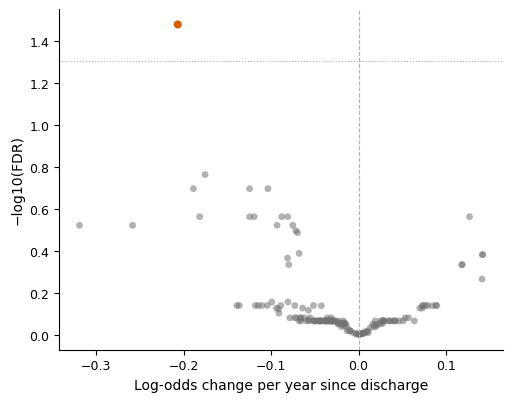

In [13]:
# Compact peptide-level effect plot for time since discharge
plot_df=pep_results.loc[pep_results['status']=='ok'].copy()
plot_df['neglog10FDR']=-np.log10(plot_df['FDR_time'].clip(lower=1e-300))
fig, ax=plt.subplots(figsize=(5.2,4.1))
ax.scatter(plot_df['beta_time'],plot_df['neglog10FDR'],s=24,alpha=.55,color='0.45',edgecolor='none')
sig=plot_df['FDR_time']<.05
ax.scatter(plot_df.loc[sig,'beta_time'],plot_df.loc[sig,'neglog10FDR'],s=34,color=SURVIVOR_COLOR,edgecolor='none')
ax.axvline(0,color='0.7',lw=.8,ls='--')
ax.axhline(-np.log10(.05),color='0.7',lw=.8,ls=':')
ax.set_xlabel('Log-odds change per year since discharge')
ax.set_ylabel('−log10(FDR)')
fig.tight_layout()
fig.savefig(OUTDIR/'peptide_time_since_discharge_effects.svg',bbox_inches='tight')
plt.show()


In [14]:
# Export analysis tables
analysis.to_csv(OUTDIR/'survivor_DoDis_analysis_dataset.csv',index=False)
corr.to_csv(OUTDIR/'DoDis_unadjusted_correlations.csv',index=False)
whole_models.to_csv(OUTDIR/'DoDis_adjusted_whole_assay_models.csv',index=False)
pep_results.to_csv(OUTDIR/'DoDis_peptide_logistic_models.csv',index=False)
print('Saved outputs to',OUTDIR)


Saved outputs to output_figures/DoDis_analysis


## Interpretation guide

- **Peptide OR_time < 1:** recognition becomes less likely with each additional year since discharge (candidate waning epitope).
- **Peptide OR_time > 1:** recognition becomes more likely with time; interpret cautiously because this is cross-sectional, not a within-person longitudinal trajectory.
- **Age and time since discharge should be interpreted from the adjusted model**, especially if they correlate in cohort QC.
- A cross-sectional DoDis association is evidence of association with time since infection, not direct proof of within-person antibody decay.
- If multiple longitudinal samples per survivor are analyzed later, replace these baseline models with mixed-effects/GEE models that account for repeated participant measurements.
